# Reading the UniversalIQTest aggregate data

**Frozen snapshot: 14 November 2026.** This worked example loads all ten aggregate CSVs, checks their hashes, reproduces the headline counts, and plots age coverage and quality-pass rates. It also checks the arithmetic behind the exported score summaries.

Source: [UniversalIQTest dataset overview](https://www.universaliqtest.com/dataset-overview-and-sources). Cite the frozen release: [10.5281/zenodo.24217581](https://doi.org/10.5281/zenodo.24217581). Data and this example: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

These are **group aggregates from a self-selected online cohort**. Quality checks do not establish clinical accuracy or independent psychometric validation. No independent external psychometric assessment has been performed. The records do not certify unique people, and there are no participant-level rows in the release.

The notebook uses the attached dataset, without internet access. To run it locally, extract the November ZIP and set `UIQ_DATASET_DIR` to that directory before starting Jupyter. A future dataset version must not silently replace this snapshot.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SNAPSHOT = "2026-11-14"
if os.environ.get("UIQ_DATASET_DIR"):
    roots = [Path(os.environ["UIQ_DATASET_DIR"])]
elif Path("manifest.json").is_file():
    roots = [Path.cwd()]
else:
    roots = [p.parent for p in Path("/kaggle/input").rglob("manifest.json")]

matches = []
for root in roots:
    manifest_path = root / "manifest.json"
    if manifest_path.is_file():
        candidate = json.loads(manifest_path.read_text(encoding="utf-8"))
        if candidate.get("publication", {}).get("version") == SNAPSHOT:
            matches.append((root, candidate))
assert len(matches) == 1, "Attach exactly one 14 November 2026 snapshot, or set UIQ_DATASET_DIR."
DATA_ROOT, manifest = matches[0]
assert manifest["methodology"]["identifier"] == "individual-score-sd-v2"
assert len(manifest["files"]) == 10

tables = {}
inventory = []
for entry in manifest["files"]:
    path = DATA_ROOT / entry["file"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == entry["sha256"], path.name
    # Preserve source codes such as NA; an empty numeric field remains missing.
    frame = pd.read_csv(path, keep_default_na=False, na_values=[""])
    assert list(frame.columns) == entry["columns"], path.name
    assert len(frame) == entry["rows"], path.name
    tables[path.stem] = frame
    inventory.append({"file": path.name, "dimension": entry["dimension"],
                      "view": entry["view"], "group_rows": len(frame)})

evidence_path = DATA_ROOT / manifest["evidence"]["file"]
assert hashlib.sha256(evidence_path.read_bytes()).hexdigest() == manifest["evidence"]["sha256"]
moments = json.loads(evidence_path.read_text(encoding="utf-8"))["groups"]
assert sum(len(t) for t in tables.values()) == 482
print(f"Verified {len(tables)} CSV hashes and the aggregate score-moments hash.")
print(f"Capture: {manifest['capturedAt']}")
display(pd.DataFrame(inventory))

Verified 10 CSV hashes and the aggregate score-moments hash.
Capture: 2026-11-14T09:40:28.956Z


,file,dimension,view,group_rows
0,country-validated.csv,country,validated,192
1,country-all.csv,country,all,216
2,age-validated.csv,age,validated,4
3,age-all.csv,age,all,4
4,gender-validated.csv,gender,validated,2
5,gender-all.csv,gender,all,2
6,education-level-validated.csv,education-level,validated,6
7,education-level-all.csv,education-level,all,6
8,study-area-validated.csv,study-area,validated,25
9,study-area-all.csv,study-area,all,25


## 1. Reproduce the headline counts

The four age bands partition the included reference cohort, so their `n` values reproduce the headline denominator. Other demographic tables cover subsets of that same cohort. Do not add counts across dimensions or across the two views: the same records contribute to several tables.

The policy introduced on **10 November 2026** excludes recognised repeats, uncertain identity matches, unverifiable responses and test data before the included count is calculated. The passing-quality view selects a subset of those included records. The October release used earlier counting and scoring rules and is not directly comparable.

In [2]:
age_all = tables["age-all"]
age_pass = tables["age-validated"]
included = int(age_all["n"].sum())
passed = int(age_pass["n"].sum())
assert (included, passed) == (216_773, 94_224)
quality_pass_rate = passed / included

print(f"Included reference-cohort tests: {included:,}")
print(f"Passed current quality checks: {passed:,}")
print(f"Quality-pass rate within the included cohort: {quality_pass_rate:.2%}")

coverage_rows = [{"dimension": "Age (headline partition)", "included": included, "passed": passed}]
for dimension, prefix in [("Country", "country"), ("Gender", "gender"),
                           ("Education", "education-level"), ("Study area", "study-area")]:
    frame = tables[f"{prefix}-all"]
    coverage_rows.append({"dimension": dimension, "included": int(frame["allN"].sum()),
                          "passed": int(frame["validatedN"].sum())})
coverage = pd.DataFrame(coverage_rows)
coverage["included_coverage_pct"] = 100 * coverage["included"] / included
display(coverage.round({"included_coverage_pct": 2}))

Included reference-cohort tests: 216,773
Passed current quality checks: 94,224
Quality-pass rate within the included cohort: 43.47%


,dimension,included,passed,included_coverage_pct
0,Age (headline partition),216773,94224,100.00
1,Country,216556,94092,99.90
2,Gender,215647,93763,99.48
3,Education,215251,93604,99.30
4,Study area,213317,92737,98.41


## 2. Age coverage and quality-pass rates

The count chart shows how much data is available in each self-reported age band. The second chart uses the matching included count in each band as its denominator. These rates describe the records retained under this policy. They do not explain why a particular record failed, or establish an effect of age on test quality.

,ageRange,included,passed,quality_pass_pct
0,12-18,84739,26522,31.30
1,19-35,80717,38461,47.65
2,36-65,46262,27185,58.76
3,66-100,5055,2056,40.67


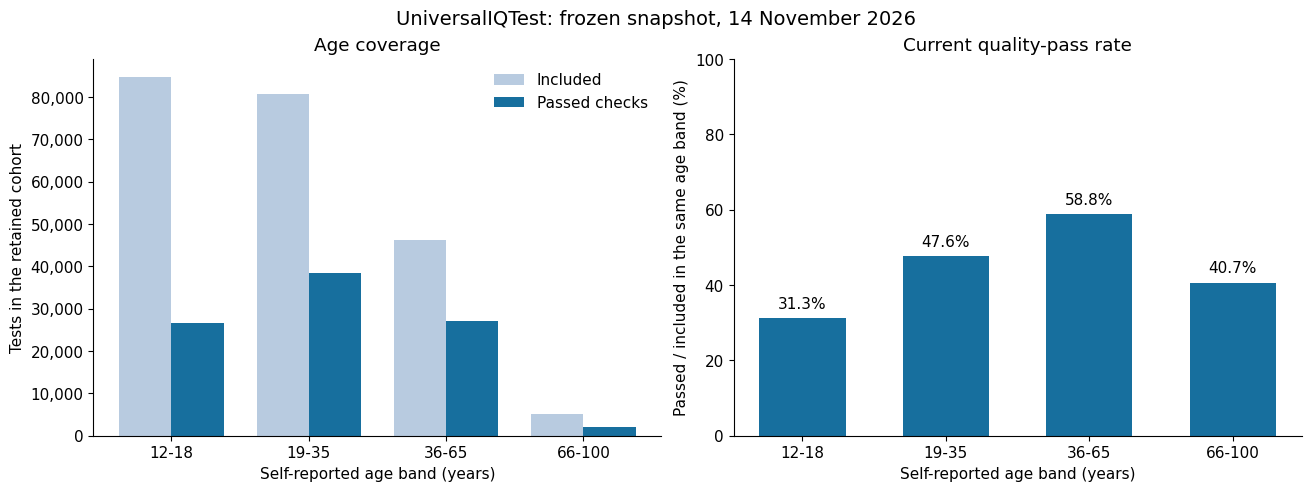

In [3]:
age = age_all[["ageCategory", "ageRange", "n"]].rename(columns={"n": "included"}).merge(
    age_pass[["ageCategory", "ageRange", "n"]].rename(columns={"n": "passed"}),
    on=["ageCategory", "ageRange"], validate="one_to_one"
)
assert (age["passed"] <= age["included"]).all()
age["quality_pass_pct"] = 100 * age["passed"] / age["included"]
display(age[["ageRange", "included", "passed", "quality_pass_pct"]].round({"quality_pass_pct": 2}))

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
x = np.arange(len(age))
axes[0].bar(x - 0.19, age["included"], width=0.38, color="#B8CBE0", label="Included")
axes[0].bar(x + 0.19, age["passed"], width=0.38, color="#176F9E", label="Passed checks")
axes[0].set_xticks(x, age["ageRange"])
axes[0].set_ylabel("Tests in the retained cohort")
axes[0].set_xlabel("Self-reported age band (years)")
axes[0].set_title("Age coverage")
axes[0].legend(frameon=False)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

bars = axes[1].bar(x, age["quality_pass_pct"], color="#176F9E", width=0.6)
axes[1].set_xticks(x, age["ageRange"])
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Passed / included in the same age band (%)")
axes[1].set_xlabel("Self-reported age band (years)")
axes[1].set_title("Current quality-pass rate")
axes[1].bar_label(bars, labels=[f"{v:.1f}%" for v in age["quality_pass_pct"]], padding=5)
fig.suptitle("UniversalIQTest: frozen snapshot, 14 November 2026", fontsize=14)
fig.savefig("age-coverage-and-screening.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Group means and individual spread

The next chart shows the exported means and middle 50% ranges in the quality-screened age table. The horizontal bars run from the 25th to the 75th percentile. They are **interquartile ranges, not confidence intervals**. They do not show individual observations. Their overlap is not a hypothesis test.

The age table uses global percentiles; country, education and study-area tables use age-normalized percentiles. Each view has its own reference distribution. A comparison between views mixes selection and normalization, so this notebook does not interpret a change of mean as the causal effect of screening. These are cross-sectional groups, not measurements of the same people as they age.

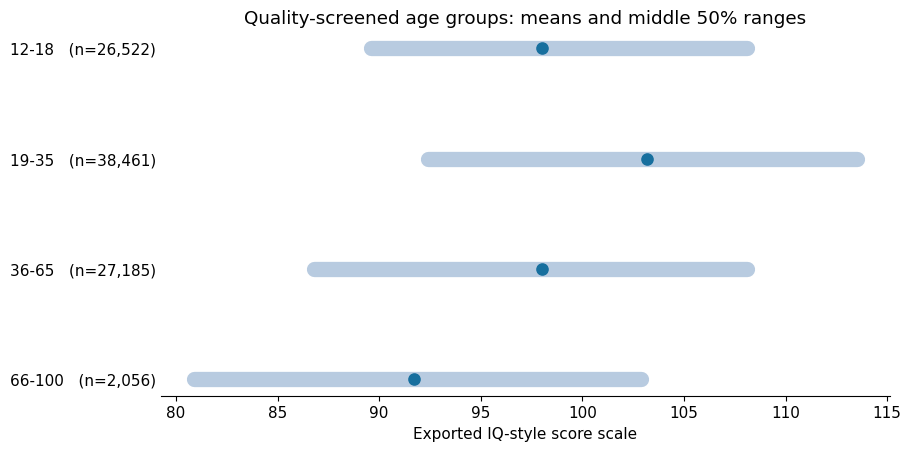

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.4), constrained_layout=True)
for y, row in age_pass.iterrows():
    ax.plot([row["p25"], row["p75"]], [y, y], color="#B8CBE0", linewidth=11, solid_capstyle="round")
    ax.scatter(row["meanIQ"], y, color="#176F9E", s=65, zorder=3)
ax.set_yticks(range(len(age_pass)), [f"{r.ageRange}   (n={r.n:,})" for r in age_pass.itertuples()])
ax.invert_yaxis()
ax.set_xlabel("Exported IQ-style score scale")
ax.set_title("Quality-screened age groups: means and middle 50% ranges")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.savefig("age-score-spread.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Check the published arithmetic

For each group, aggregate score moments contain `n`, the sum of individual scaled scores and the sum of their squares. They let us reproduce the arithmetic mean and sample standard deviation without publishing individual rows. The exported values are rounded to one decimal place.

Where a table exports interval columns and the group has at least two records, the released calculation is `meanIQ ± 1.96 × stddevIQ / sqrt(n)`, using the rounded exported mean and sample SD. Age CSVs have no interval columns. Single-record intervals are unavailable. These approximate intervals omit selection bias, measurement error, normalization uncertainty and unrecorded prior exposure. Arithmetic reproduction does not validate their population coverage or the underlying measurement model.

In [5]:
moment_index = {(m["file"], str(m["category"])): m for m in moments}
checks = {"group_means_and_sample_sds": 0, "screening_rates": 0, "available_intervals": 0}

def round_one(value):
    # Match the positive-score rounding used by the published calculation.
    return math.floor(value * 10 + 0.5) / 10

for entry in manifest["files"]:
    frame = tables[Path(entry["file"]).stem]
    key_column = entry["columns"][0]
    for _, row in frame.iterrows():
        n = int(row["n"] if "n" in row else row["validatedN"] if entry["view"] == "validated" else row["allN"])
        moment = moment_index[(entry["file"], str(row[key_column]))]
        assert moment["n"] == n
        assert math.isclose(row["meanIQ"], round_one(moment["scoreSum"] / n), abs_tol=1e-8)
        if n > 1:
            variance = max(0, (moment["scoreSquaredSum"] - moment["scoreSum"] ** 2 / n) / (n - 1))
            assert math.isclose(row["stddevIQ"], round_one(math.sqrt(variance)), abs_tol=1e-8)
        else:
            assert pd.isna(row["stddevIQ"])
        checks["group_means_and_sample_sds"] += 1

        if "validationRate" in row:
            expected_rate = round_one(100 * row["validatedN"] / row["allN"])
            assert math.isclose(row["validationRate"], expected_rate, abs_tol=1e-8)
            checks["screening_rates"] += 1
        if "ciLower" in row:
            if n > 1:
                margin = 1.96 * row["stddevIQ"] / math.sqrt(n)
                assert math.isclose(row["ciLower"], row["meanIQ"] - margin, abs_tol=1e-7)
                assert math.isclose(row["ciUpper"], row["meanIQ"] + margin, abs_tol=1e-7)
                checks["available_intervals"] += 1
            else:
                assert pd.isna(row["ciLower"]) and pd.isna(row["ciUpper"])

assert checks == {"group_means_and_sample_sds": 482, "screening_rates": 474, "available_intervals": 437}
display(pd.DataFrame([checks]))
print("All published group summaries and available intervals reproduced.")

,group_means_and_sample_sds,screening_rates,available_intervals
0,482,474,437


All published group summaries and available intervals reproduced.


## Reuse and interpretation

Use this example to teach denominators, missing category coverage, overlap of group distributions and the distinction between numerical precision and population validity. It cannot establish national intelligence, a clinical diagnosis, individual score distributions or causal effects of age, education or screening. Country labels include legacy source codes that need review before mapping.

The cohort was captured at **2026-11-14 09:40:28.956 UTC**; the latest included submission was **2026-11-14 01:57:24.926 UTC**. The counts are a frozen reference, while the live website can change.

**Citation:** UniversalIQTest. (2026). *Online matrix-reasoning test performance: aggregate snapshot, 14 November 2026* (Version 2026-11-14) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.24217581

Documentation: [methodology review](https://github.com/SerdilMordeniz/universaliqtest-aggregate-data/blob/snapshot-2026-11-14/methodology-review.md), [data dictionary](https://github.com/SerdilMordeniz/universaliqtest-aggregate-data/blob/snapshot-2026-11-14/data-dictionary.md), and [frozen GitHub release](https://github.com/SerdilMordeniz/universaliqtest-aggregate-data/releases/tag/snapshot-2026-11-14). Licence: **CC BY 4.0**, attribution to UniversalIQTest and the frozen DOI.